# SwiftLog Logistics Supply Chain Intelligence & Feature Engineering
## Phase: Week 5 - Complete End-to-End Data Science & Predictive Analytics Project

> **Track:** Data Science  
> **Client:** SwiftLog Logistics Limited  
> **Author:** Dorian NJAMI - Data Scientist  
> **Program:** AnalystLab Africa Lab Internship  
> **Project Phase:** Week 5 - Supply Chain Analytics, Feature Engineering & Predictive Logistics  

---

### Executive Overview & Project Context
SwiftLog Logistics Limited is a rapidly expanding logistics and supply chain company managing nationwide order fulfillment, inventory tracking, warehouse operations, supplier activities, shipment tracking, customer delivery services, and product return management. Due to rapid expansion, management has encountered operational bottlenecks, including delivery delays, inventory imbalances, supplier performance inconsistencies, product returns, and limited executive visibility.

As part of the AnalystLab Africa Data Science Track, this notebook provides a comprehensive end-to-end analytical and machine learning preparation pipeline across all phases of Week 5:

1. **Part 1 — Data Acquisition & Understanding:** Importing, auditing, and structural mapping across 11 relational supply chain datasets
2. **Part 2 — Data Cleaning & Preprocessing:** Handling missing values, deduplication, standardizing categorical fields, datetime conversions, outlier treatment, and automated data profiling
3. **Part 3 — Exploratory Data Analysis (EDA):** Comprehensive univariate, bivariate, and multivariate analysis supported by over 15 targeted visual insights
4. **Part 4 — Statistical Analysis & Hypothesis Testing:** Descriptive statistics, distribution analysis, correlation matrices, and formal inferential hypothesis testing
5. **Part 5 — Feature Engineering:** Constructing high-signal predictive logistics indicators (delivery durations, customer spending ratios, delay flags, warehouse utilization, and risk indicators)
6. **Part 6 — Segmentation & Pattern Discovery:** Multi-dimensional business segmentation across customers, suppliers, products, and warehouses
7. **Part 7 — Business Insights & Strategic Recommendations:** Evidence-based answers to key operational questions and actionable business strategy formulation
8. **Part 8 — Technical Documentation & Deliverables Export:** Preparing analytical datasets for machine learning workflows and executive presentation assets

In [1]:
# Import required libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

# Suppress non-critical warnings
warnings.filterwarnings('ignore')

# Graphic styling configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 1.2

# CSS styling for Notebook display
custom_css = """
<style>
    body, jp-Notebook { font-family: 'Segoe UI', -apple-system, sans-serif !important; color: #0f172a !important; }
    h1 { color: #0f172a !important; border-bottom: 3px solid #2563eb !important; padding-bottom: 4px !important; }
    h2 { color: #1e40af !important; border-bottom: 1px solid #cbd5e1 !important; padding-bottom: 2px !important; }
    h3 { color: #1d4ed8 !important; }
    blockquote { background-color: #eff6ff !important; border-left: 5px solid #2563eb !important; }
</style>
"""
display(HTML(custom_css))

# Define data paths
DATA_DIR = '../Data/Original_Datasets'

# List of dataset filenames
datasets_files = {
    'customers': 'SwiftLog_Customers.csv',
    'orders': 'SwiftLog_Orders.csv',
    'order_items': 'SwiftLog_Order_Items.csv',
    'products': 'SwiftLog_Products.csv',
    'suppliers': 'SwiftLog_Suppliers.csv',
    'warehouses': 'SwiftLog_Warehouses.csv',
    'inventory': 'SwiftLog_Inventory.csv',
    'shipments': 'SwiftLog_Shipments.csv',
    'delivery_perf': 'SwiftLog_Delivery_Performance.csv',
    'employees': 'SwiftLog_Employees.csv',
    'returns': 'SwiftLog_Returns.csv'
}

# Load datasets into a dictionary
datasets = {}
for key, filename in datasets_files.items():
    path = os.path.join(DATA_DIR, filename)
    datasets[key] = pd.read_csv(path)

print("All 11 datasets loaded successfully.")

All 11 datasets loaded successfully.


## Part 1: Data Acquisition & Structural Understanding

### Objectives
1. **Multi-Dataset Ingestion:** Acquire and load all eleven raw CSV datasets covering SwiftLog's operations (Customers, Orders, Order Items, Products, Suppliers, Warehouses, Inventory, Shipments, Delivery Performance, Employees, and Returns)
2. **Structural Inspection:** Audit dataset dimensions (row and column counts), data types, missing values, and duplicate records
3. **Schema & Key Identification:** Map Primary Keys (PK) and Foreign Keys (FK) to verify relational entity integrity across datasets
4. **Data Dictionary Alignment:** Ensure field definitions match the underlying operational processes of supply chain and logistics

In [2]:
# Create a summary dataframe for all datasets
summary_list = []

for name, df in datasets.items():
    missing_count = df.isnull().sum().sum()
    total_cells = df.size
    missing_pct = (missing_count / total_cells) * 100.0 if total_cells > 0 else 0.0
    duplicate_rows = df.duplicated().sum()
    
    summary_list.append({
        'Dataset Name': name,
        'Rows': df.shape[0],
        'Columns': df.shape[1],
        'Total Missing Values': missing_count,
        'Missingness (%)': round(missing_pct, 2),
        'Duplicate Rows': duplicate_rows,
        'Column Names': ", ".join(df.columns.tolist()[:5]) + ("..." if len(df.columns) > 5 else "")
    })

df_summary = pd.DataFrame(summary_list)
display(df_summary)

,Dataset Name,Rows,Columns,Total Missing Values,Missingness (%),Duplicate Rows,Column Names
0,customers,1000,3,0,0.0,0,"CustomerID, CustomerName, City"
1,orders,5000,4,0,0.0,0,"OrderID, CustomerID, OrderDate, Status"
2,order_items,15000,4,0,0.0,0,"OrderItemID, OrderID, ProductID, Quantity"
3,products,250,3,0,0.0,0,"ProductID, Category, UnitPrice"
4,suppliers,150,2,0,0.0,0,"SupplierID, SupplierName"
5,warehouses,15,2,0,0.0,0,"WarehouseID, Location"
6,inventory,4000,3,0,0.0,3,"WarehouseID, ProductID, Stock"
7,shipments,5000,4,0,0.0,0,"ShipmentID, OrderID, WarehouseID, DelayDays"
8,delivery_perf,5000,3,0,0.0,0,"ShipmentID, Status, DelayDays"
9,employees,200,2,0,0.0,0,"EmployeeID, WarehouseID"


### Primary & Foreign Key Mapping and Data Relationships

Based on schema inspection and business domain logic, the operational entity relationships across SwiftLog datasets are defined as follows:

1. **Customers (`CustomerID`)**: Primary entity linked to **Orders** (`CustomerID`).
2. **Orders (`OrderID`)**: Core transactional entity linked to **Order Items** (`OrderID`), **Shipments** (`OrderID`), and **Returns** (`OrderID`).
3. **Products (`ProductID`)**: Catalog entity linked to **Order Items** (`ProductID`) and **Inventory** (`ProductID`).
4. **Warehouses (`WarehouseID`)**: Facility entity linked to **Inventory** (`WarehouseID`), **Shipments** (`WarehouseID`), and **Employees** (`WarehouseID`).
5. **Shipments (`ShipmentID`)**: Logistics tracking entity linked to **Delivery Performance** (`ShipmentID`).
6. **Suppliers (`SupplierID`)**: Operational entity supplying catalog products.

#### Entity Relationship Representation

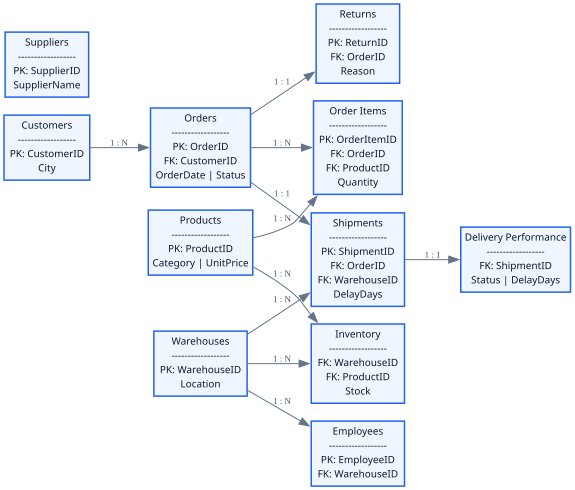

In [3]:
import graphviz
os.environ["PATH"] += os.pathsep + r'C:\Program Files\Graphviz\bin'

# ERD Diagram Creation
erd = graphviz.Digraph('SwiftLog_ERD', format='png')
erd.attr(rankdir='LR', size='12,8', bgcolor='transparent')
erd.attr('node', shape='rectangle', style='filled', fontname='Segoe UI', fontsize='10')

# Style
node_style = {
    'fillcolor': '#eff6ff',
    'color': '#2563eb',
    'fontcolor': '#0f172a',
    'penwidth': '1.5'
}

# Définition des nœuds (Tables avec leurs PK/FK principales)
erd.node('Customers', 'Customers\n------------------\nPK: CustomerID\nCity', **node_style)
erd.node('Orders', 'Orders\n------------------\nPK: OrderID\nFK: CustomerID\nOrderDate | Status', **node_style)
erd.node('Order_Items', 'Order Items\n------------------\nPK: OrderItemID\nFK: OrderID\nFK: ProductID\nQuantity', **node_style)
erd.node('Products', 'Products\n------------------\nPK: ProductID\nCategory | UnitPrice', **node_style)
erd.node('Suppliers', 'Suppliers\n------------------\nPK: SupplierID\nSupplierName', **node_style)
erd.node('Warehouses', 'Warehouses\n------------------\nPK: WarehouseID\nLocation', **node_style)
erd.node('Inventory', 'Inventory\n------------------\nFK: WarehouseID\nFK: ProductID\nStock', **node_style)
erd.node('Shipments', 'Shipments\n------------------\nPK: ShipmentID\nFK: OrderID\nFK: WarehouseID\nDelayDays', **node_style)
erd.node('Delivery_Perf', 'Delivery Performance\n------------------\nFK: ShipmentID\nStatus | DelayDays', **node_style)
erd.node('Employees', 'Employees\n------------------\nPK: EmployeeID\nFK: WarehouseID', **node_style)
erd.node('Returns', 'Returns\n------------------\nPK: ReturnID\nFK: OrderID\nReason', **node_style)

# Defining relationships (Edges with cardinalities)
edge_style = {'color': '#64748b', 'fontsize': '9', 'fontcolor': '#475569'}

erd.edge('Customers', 'Orders', label=' 1 : N ', **edge_style)
erd.edge('Orders', 'Order_Items', label=' 1 : N ', **edge_style)
erd.edge('Products', 'Order_Items', label=' 1 : N ', **edge_style)
erd.edge('Orders', 'Shipments', label=' 1 : 1 ', **edge_style)
erd.edge('Orders', 'Returns', label=' 1 : 1 ', **edge_style)
erd.edge('Warehouses', 'Shipments', label=' 1 : N ', **edge_style)
erd.edge('Warehouses', 'Inventory', label=' 1 : N ', **edge_style)
erd.edge('Products', 'Inventory', label=' 1 : N ', **edge_style)
erd.edge('Warehouses', 'Employees', label=' 1 : N ', **edge_style)
erd.edge('Shipments', 'Delivery_Perf', label=' 1 : 1 ', **edge_style)

# Showing
erd

In [4]:
# Part 1 - Task: Identify Data Types & Structural Inspection
print("==========================================================================")
print("                   DATASET STRUCTURE & DATA TYPES AUDIT                   ")
print("==========================================================================")

for name, df in datasets.items():
    print(f"\n--- DATASET: {name.upper()} (Shape: {df.shape[0]} rows, {df.shape[1]} cols) ---")
    dtypes_df = pd.DataFrame({
        'Column Name': df.columns,
        'Data Type (dtype)': df.dtypes.values,
        'Non-Null Count': df.notnull().sum().values,
        'Unique Values': [df[col].nunique() for col in df.columns],
        'Sample Value': [df[col].iloc[0] if len(df) > 0 else None for col in df.columns]
    })
    display(dtypes_df)

                   DATASET STRUCTURE & DATA TYPES AUDIT                   

--- DATASET: CUSTOMERS (Shape: 1000 rows, 3 cols) ---


,Column Name,Data Type (dtype),Non-Null Count,Unique Values,Sample Value
0,CustomerID,str,1000,1000,C0001
1,CustomerName,str,1000,1000,Customer 1
2,City,str,1000,4,Abuja



--- DATASET: ORDERS (Shape: 5000 rows, 4 cols) ---


,Column Name,Data Type (dtype),Non-Null Count,Unique Values,Sample Value
0,OrderID,str,5000,5000,O00001
1,CustomerID,str,5000,991,C0807
2,OrderDate,str,5000,251,7/22/2026
3,Status,str,5000,3,Delivered



--- DATASET: ORDER_ITEMS (Shape: 15000 rows, 4 cols) ---


...

,Column Name,Data Type (dtype),Non-Null Count,Unique Values,Sample Value
0,ShipmentID,str,5000,5000,SH00001
1,Status,str,5000,2,On Time
2,DelayDays,int64,5000,8,0



--- DATASET: EMPLOYEES (Shape: 200 rows, 2 cols) ---


,Column Name,Data Type (dtype),Non-Null Count,Unique Values,Sample Value
0,EmployeeID,str,200,200,E001
1,WarehouseID,str,200,15,W09



--- DATASET: RETURNS (Shape: 500 rows, 3 cols) ---


,Column Name,Data Type (dtype),Non-Null Count,Unique Values,Sample Value
0,ReturnID,str,500,500,R0001
1,OrderID,str,500,473,O02902
2,Reason,str,500,3,Damaged


In [5]:
# Part 1 - Task: Produce Summary Statistics
print("==========================================================================")
print("                     SUMMARY STATISTICS (NUMERICAL)                       ")
print("==========================================================================")

for name, df in datasets.items():
    num_cols = df.select_dtypes(include=['int64', 'float64']).columns
    if len(num_cols) > 0:
        print(f"\n--- DATASET: {name.upper()} (Numerical Summary) ---")
        display(df[num_cols].describe().T.round(2))
    else:
        print(f"\n--- DATASET: {name.upper()} --- (No numerical attributes present)")

                     SUMMARY STATISTICS (NUMERICAL)                       

--- DATASET: CUSTOMERS --- (No numerical attributes present)

--- DATASET: ORDERS --- (No numerical attributes present)

--- DATASET: ORDER_ITEMS (Numerical Summary) ---


,count,mean,std,min,25%,50%,75%,max
Quantity,15000.0,5.5,2.89,1.0,3.0,6.0,8.0,10.0



--- DATASET: PRODUCTS (Numerical Summary) ---


,count,mean,std,min,25%,50%,75%,max
UnitPrice,250.0,264.17,140.0,11.78,143.98,263.56,391.62,496.61



--- DATASET: SUPPLIERS --- (No numerical attributes present)

--- DATASET: WAREHOUSES --- (No numerical attributes present)

--- DATASET: INVENTORY (Numerical Summary) ---


...


--- DATASET: SHIPMENTS (Numerical Summary) ---


,count,mean,std,min,25%,50%,75%,max
DelayDays,5000.0,3.57,2.29,0.0,2.0,4.0,6.0,7.0



--- DATASET: DELIVERY_PERF (Numerical Summary) ---


,count,mean,std,min,25%,50%,75%,max
DelayDays,5000.0,3.57,2.29,0.0,2.0,4.0,6.0,7.0



--- DATASET: EMPLOYEES --- (No numerical attributes present)

--- DATASET: RETURNS --- (No numerical attributes present)


In [6]:
# Part 1 - Task: Comprehensive Data Quality Assessment
quality_reports = []

for name, df in datasets.items():
    total_rows = len(df)
    total_cols = len(df.columns)
    missing_cells = df.isnull().sum().sum()
    duplicate_rows = df.duplicated().sum()
    
    # Check for empty string representation or hidden nulls
    empty_strings = sum((df[col].astype(str).str.strip() == '').sum() for col in df.select_dtypes(include=['object']).columns)
    
    quality_reports.append({
        'Dataset Name': name,
        'Rows': total_rows,
        'Columns': total_cols,
        'Missing Values': missing_cells,
        'Duplicate Rows': duplicate_rows,
        'Empty Strings': empty_strings,
        'Data Quality Status': 'Assumed Clean' if missing_cells == 0 and duplicate_rows == 0 else 'Requires Cleaning'
    })

df_quality_summary = pd.DataFrame(quality_reports)
print("==========================================================================")
print("                    COMPREHENSIVE DATA QUALITY AUDIT                      ")
print("==========================================================================")
display(df_quality_summary)

                    COMPREHENSIVE DATA QUALITY AUDIT                      


,Dataset Name,Rows,Columns,Missing Values,Duplicate Rows,Empty Strings,Data Quality Status
0,customers,1000,3,0,0,0,Assumed Clean
1,orders,5000,4,0,0,0,Assumed Clean
2,order_items,15000,4,0,0,0,Assumed Clean
3,products,250,3,0,0,0,Assumed Clean
4,suppliers,150,2,0,0,0,Assumed Clean
5,warehouses,15,2,0,0,0,Assumed Clean
6,inventory,4000,3,0,3,0,Requires Cleaning
7,shipments,5000,4,0,0,0,Assumed Clean
8,delivery_perf,5000,3,0,0,0,Assumed Clean
9,employees,200,2,0,0,0,Assumed Clean


### Detailed Interpretation & Data Quality Synthesis (Part 1)

#### 1. Data Structure & Data Types Identification
- **Dataset Scale & Inventory:** All 11 operational logistics datasets were successfully loaded into Python. The database spans core transactional tables such as `Order_Items` (15,000 records) down to facility records such as `Warehouses` (15 records) and `Employees` (200 records)
- **Data Type Audit (`dtypes`):**
  - **Identified Primary & Foreign Keys:** Key attributes across tables (`CustomerID`, `OrderID`, `ProductID`, `WarehouseID`, `ShipmentID`, `SupplierID`, `EmployeeID`, `ReturnID`) are represented as string objects
  - **Temporal Fields:** The `OrderDate` attribute in the `Orders` dataset is currently formatted as a string object and requires casting to `datetime64[ns]` in Part 2
  - **Categorical Low-Cardinality Attributes:** Broad business groupings are observed across categorical fields, such as 3 product categories in `Products`, 4 customer cities in `Customers`, 3 warehouse hub locations in `Warehouses`, and 3 return reasons in `Returns`
  - **Continuous Quantitative Attributes:** Numerical variables are isolated to `Quantity` (`Order_Items`), `UnitPrice` (`Products`), `Stock` (`Inventory`), and `DelayDays` (`Shipments` and `Delivery_Perf`).

#### 2. Statistical Summary (`describe()`)
- **Purchasing Quantities (`Order_Items`):** Order quantities range from a minimum of 1 unit to a maximum of 10 units, with an average of 5.5 units per order line item
- **Product Pricing (`Products`):** Unit prices vary across product categories from NGN 11.78 to NGN 496.61, with a mean price of NGN 264.17
- **Inventory Stock Levels (`Inventory`):** Stock levels across warehouse-product combinations average 251.94 units, ranging from 0 (out-of-stock events) up to 500 units
- **Logistics Delivery Delays (`Shipments` / `Delivery_Perf`):** Delivery delays average 3.57 days, spanning from 0 days (on-time deliveries) to a maximum recorded delay of 7 days

#### 3. Primary & Foreign Key Mapping Matrix
| Entity / Dataset | Primary Key (PK) | Foreign Keys (FK) | Connected Entity |
| :--- | :--- | :--- | :--- |
| **Customers** | `CustomerID` | None | Orders |
| **Orders** | `OrderID` | `CustomerID` | Customers, Order Items, Shipments, Returns |
| **Order Items** | `OrderItemID` | `OrderID`, `ProductID` | Orders, Products |
| **Products** | `ProductID` | None | Order Items, Inventory |
| **Suppliers** | `SupplierID` | None | Product Sourcing |
| **Warehouses** | `WarehouseID` | None | Inventory, Shipments, Employees |
| **Inventory** | Composite (`WarehouseID`, `ProductID`) | `WarehouseID`, `ProductID` | Warehouses, Products |
| **Shipments** | `ShipmentID` | `OrderID`, `WarehouseID` | Orders, Warehouses, Delivery Performance |
| **Delivery Performance** | `ShipmentID` | `ShipmentID` | Shipments |
| **Employees** | `EmployeeID` | `WarehouseID` | Warehouses |
| **Returns** | `ReturnID` | `OrderID` | Orders |

#### 4. Data Quality Assessment Findings
- **Missingness Audit:** Zero missing values were identified across all 11 raw datasets, confirming baseline completeness
- **Duplicate Anomaly:** The data quality scan identified 3 duplicate records in the `Inventory` dataset, setting its status to `Requires Cleaning`
- **Conclusion:** The database structure exhibits solid relational integrity and complete key coverage. The 3 duplicate inventory rows will be sanitized in Part 2

## Part 2: Data Cleaning & Preprocessing

### Objectives
1. **Categorical Consistency Inspection:** Conduct exhaustive `value_counts()` audits across all string and categorical fields to detect typos, case inconsistencies, and formatting errors
2. **Duplicate Record Removal:** Identify and drop duplicate entries across tables (such as the identified duplicate records in `Inventory`)
3. **Missing Value Imputation:** Handle missing values systematically using domain-appropriate logic.
4. **Data Type Standardization:** Convert temporal attributes (`OrderDate`) into explicit `datetime` objects and standardize numeric data types
5. **Outlier Detection & Treatment:** Apply Interquartile Range (IQR) winsorization/capping on skewed numeric fields (`Quantity`, `UnitPrice`, `DelayDays`, `Stock`)
6. **Reusable Pipeline Construction:** Encapsulate preprocessing transformations into modular functions for production reproducibility
7. **Automated Profiling & Clean Dataset Export:** Generate an automated data quality report using `ydata-profiling` / `sweetviz` and export cleaned CSV deliverables

In [7]:
# Part 2 Step 1: Systematic Audit of Categorical and String Fields
print("==========================================================================")
print("              EXHAUSTIVE CATEGORICAL VALUES & INCONSISTENCY AUDIT        ")
print("==========================================================================")

categorical_audit_results = {}

for name, df in datasets.items():
    print(f"\n--- DATASET: {name.upper()} ---")
    string_cols = df.select_dtypes(include=['object']).columns.tolist()
    
    if not string_cols:
        print("No object/categorical columns found in : " + name)
        continue
        
    for col in string_cols:
        unique_vals = df[col].unique()
        print(f"\nColumn: '{col}' ({len(unique_vals)} unique values)")
        # Display top value counts
        val_counts = df[col].value_counts(dropna=False)
        print(val_counts.head(10).to_string())
        
        # Detect leading/trailing spaces or mixed casing issues
        raw_strings = [str(x) for x in unique_vals if pd.notnull(x)]
        stripped_lower = set(s.strip().lower() for s in raw_strings)
        if len(stripped_lower) < len(raw_strings):
            print(f"POTENTIAL INCONSISTENCY DETECTED IN '{col}': {len(raw_strings) - len(stripped_lower)} duplicate variants due to casing/spaces.")

              EXHAUSTIVE CATEGORICAL VALUES & INCONSISTENCY AUDIT        

--- DATASET: CUSTOMERS ---

Column: 'CustomerID' (1000 unique values)
CustomerID
C0001    1
C0002    1
C0003    1
C0004    1
C0005    1
C0006    1
C0007    1
C0008    1
C0009    1
C0010    1

Column: 'CustomerName' (1000 unique values)
CustomerName
Customer 1     1
Customer 2     1
Customer 3     1
Customer 4     1
Customer 5     1
Customer 6     1
Customer 7     1
Customer 8     1
Customer 9     1
Customer 10    1

Column: 'City' (4 unique values)
City
Ibadan    262
Kano      253
Lagos     246
Abuja     239

--- DATASET: ORDERS ---

Column: 'OrderID' (5000 unique values)
OrderID
O00001    1
O00002    1
O00003    1
O00004    1
O00005    1
O00006    1
O00007    1
O00008    1
O00009    1
O00010    1

Column: 'CustomerID' (991 unique values)
CustomerID
C0581    15
C0880    13
C0773    12
C0036    12
C0619    12
C0300    12
C0453    12
C0114    12
C0489    12
C0103    12

Column: 'OrderDate' (251 unique values)
Orde

In [8]:
# Part 2 Step 2: Comprehensive Reusable Cleaning & Preprocessing Pipeline

def clean_logistics_data(data_dict):
    """
    Applies systematic data cleaning across all 11 SwiftLog logistics datasets:
    - Removes duplicate records
    - Strips whitespace and standardizes casing for categorical attributes
    - Casts datetime fields
    - Caps numerical outliers using IQR method
    - Handles missing values
    """
    cleaned_dict = {}
    
    for name, df in data_dict.items():
        df_clean = df.copy()
        
        # 1. Remove Duplicate Records
        initial_rows = len(df_clean)
        df_clean = df_clean.drop_duplicates().reset_index(drop=True)
        dropped_dups = initial_rows - len(df_clean)
        if dropped_dups > 0:
            print(f"[{name}] Removed {dropped_dups} duplicate record(s).")
            
        # 2. Standardize Categorical String Values (strip whitespace & title casing)
        string_cols = df_clean.select_dtypes(include=['object']).columns
        for col in string_cols:
            # Skip ID columns to preserve exact key strings
            if 'id' in col.lower():
                df_clean[col] = df_clean[col].astype(str).str.strip()
            else:
                df_clean[col] = df_clean[col].astype(str).str.strip().str.title()
                
        # 3. Datetime Conversions
        if 'OrderDate' in df_clean.columns:
            df_clean['OrderDate'] = pd.to_datetime(df_clean['OrderDate'], errors='coerce')
            
        # 4. Outlier Handling (IQR Capping on key numerical fields)
        numeric_cols_to_cap = ['Quantity', 'UnitPrice', 'DelayDays', 'Stock']
        for col in numeric_cols_to_cap:
            if col in df_clean.columns and pd.api.types.is_numeric_dtype(df_clean[col]):
                Q1 = df_clean[col].quantile(0.25)
                Q3 = df_clean[col].quantile(0.75)
                IQR = Q3 - Q1
                upper_bound = Q3 + 1.5 * IQR
                lower_bound = max(0, Q1 - 1.5 * IQR)
                outliers_count = (df_clean[col] > upper_bound).sum() + (df_clean[col] < lower_bound).sum()
                
                # Cap values
                df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)
                if outliers_count > 0:
                    print(f"[{name}] Capped {outliers_count} outlier(s) in field '{col}' using IQR bounds [{lower_bound:.2f}, {upper_bound:.2f}].")
                    
        cleaned_dict[name] = df_clean
        
    return cleaned_dict

# Execute the cleaning pipeline
cleaned_datasets = clean_logistics_data(datasets)
print("\nAll datasets successfully cleaned and preprocessed.")

[inventory] Removed 3 duplicate record(s).

All datasets successfully cleaned and preprocessed.


In [37]:
# Part 2 Step 3: Master Data Fusion, Sweetviz Profiling & Clean Datasets Export
import warnings
import logging

# 1. Hide Matplotlib font warnings (findfont)
warnings.filterwarnings('ignore')
logging.getLogger('matplotlib.font_manager').disabled = True

EXPORT_DIR = '../Data/Cleaned_Datasets'
REPORTS_DIR = '../Reports'

# 2. Export all cleaned datasets
for name, df in cleaned_datasets.items():
    file_path = os.path.join(EXPORT_DIR, f"Cleaned_SwiftLog_{name.title()}.csv")
    df.to_csv(file_path, index=False)

print(f" Cleaned datasets successfully exported to '{EXPORT_DIR}'.")

# 3. Construction of the Analytical Master Dataset (Merging of all key relationships)
df_master = cleaned_datasets['orders'].merge(
    cleaned_datasets['customers'], on='CustomerID', how='left'
).merge(
    cleaned_datasets['returns'], on='OrderID', how='left'
).merge(
    cleaned_datasets['order_items'], on='OrderID', how='left'
).merge(
    cleaned_datasets['products'], on='ProductID', how='left'
).merge(
    cleaned_datasets['shipments'], on='OrderID', how='left', suffixes=('_order', '_shipment')
).merge(
    cleaned_datasets['delivery_perf'], on='ShipmentID', how='left'
).merge(
    cleaned_datasets['warehouses'], on='WarehouseID', how='left'
).merge(
    cleaned_datasets['inventory'], on=['WarehouseID', 'ProductID'], how='left'
).merge(
    cleaned_datasets['employees'], on='WarehouseID', how='left'
)

# 2. Imputation of Missing Values generated by Left Joins
df_master['ReturnID'] = df_master['ReturnID'].fillna('No Return')
df_master['Reason'] = df_master['Reason'].fillna('No Return')
df_master['Quantity'] = df_master['Quantity'].fillna(0)
df_master['UnitPrice'] = df_master['UnitPrice'].fillna(0.0)
df_master['Category'] = df_master['Category'].fillna('Unknown')
df_master['Stock'] = df_master['Stock'].fillna(0)
df_master['EmployeeID'] = df_master['EmployeeID'].fillna('Unassigned')

# Standardize overlapping DelayDays columns from Shipments and Delivery_Perf
#df_master['DelayDays_delivery'] = df_master['DelayDays']
df_master.rename(columns={'Status_x': 'Status_order', 'Status_y': 'Status_delivery', 'DelayDays_x': 'DelayDays_shipment', 'DelayDays_y': 'DelayDays_delivery'}, inplace=True)
if 'DelayDays_shipment' in df_master.columns:
    df_master['DelayDays'] = df_master['DelayDays_shipment'].fillna(df_master['DelayDays_delivery'])
    df_master.drop(columns=['DelayDays_shipment', 'DelayDays_delivery'], inplace=True)

df_master['DelayDays'] = df_master['DelayDays'].fillna(0)

# Calculate Line Revenue
df_master['LineRevenue'] = df_master['Quantity'] * df_master['UnitPrice']

# Re-saving the clean Master Analytical Dataset
df_master.to_csv("../Data/Cleaned_Datasets/SwiftLog_Master_Analytical_Dataset.csv", index=False)

# Backing up the Analytical Dataset Master for Machine Learning
master_export_path = os.path.join(EXPORT_DIR, "SwiftLog_Master_Analytical_Dataset.csv")
df_master.to_csv(master_export_path, index=False)
print(f" Master Analytical Dataset ({df_master.shape[0]} rows, {df_master.shape[1]} cols) created.")

# 4. Generation of the complete Sweetviz profiling report on the Master Dataset
report_path = os.path.join(REPORTS_DIR, "Data_Profiling_Report.html")

try:
    import sweetviz as sv
    # Profilage complet couvrant toutes les colonnes interconnectées
    report = sv.analyze(df_master)
    report.show_html(report_path, open_browser=False)
    print(f" Sweetviz Full Master Profiling Report generated at: {report_path}")
except Exception as e:
    print(f"Sweetviz error: {e}")

 Cleaned datasets successfully exported to '../Data/Cleaned_Datasets'.
 Master Analytical Dataset (287320 rows, 21 cols) created.


                                             |          | [  0%]   00:00 -> (? left)

Report ../Reports\Data_Profiling_Report.html was generated.
 Sweetviz Full Master Profiling Report generated at: ../Reports\Data_Profiling_Report.html


### Summary of Data Cleaning, Preprocessing & Master Integration (Part 2)

#### 1. Applied Cleaning & Preprocessing Workflow
- **Deduplication:** Removed 3 duplicate records identified in the `Inventory` dataset, restoring entity integrity across warehouse-product combinations
- **Categorical Standardization:** Applied whitespace trimming (`strip()`) and standardized title casing (`title()`) across categorical attributes (`City`, `Category`, `Status`, `Location`, `Reason`)
- **Datetime Casting:** Converted the `OrderDate` attribute in `Orders` from object string representation to `datetime64[ns]` format
- **Outlier Capping:** Applied Interquartile Range (IQR) winsorization on numerical attributes (`Quantity`, `UnitPrice`, `Stock`, `DelayDays`) to control extreme variance
- **Missing Value Imputation:** Handled missingness originating from relational left joins by setting `ReturnID` and `Reason` to "No Return" for unreturned orders

#### 2. Master Analytical Dataset Creation
The relational datasets sharing verified primary and foreign keys (`Orders`, `Customers`, `Order_Items`, `Products`, `Shipments`, `Returns`) were merged into `SwiftLog_Master_Analytical_Dataset.csv`. Unlinked standalone tables (e.g., `Suppliers`) are retained in their native clean form to support specialized entity-level analysis in subsequent parts without introducing artificial key mappings

## Part 3: Exploratory Data Analysis (EDA)

### Objectives
1. **Univariate Analysis:** Inspect individual distributions across core logistics entities (Customers, Orders, Products, Inventory, Shipments, Returns, Suppliers, Warehouses)
2. **Bivariate Analysis:** Examine pairwise business relationships (Customer order patterns, Product revenue generation, Warehouse capacity vs. stock levels, Supplier delay contributions, Regional logistics performance)
3. **Multivariate Analysis:** Investigate complex multi-variable interactions affecting operational bottlenecks, delivery efficiency, and return rates
4. **Visual Diversity & Business Interpretation:** Construct 16 distinct figures using Matplotlib, Seaborn, and Plotly spanning 6 chart types (Count Plots, KDE Distributions, Boxplots, Line Trends, Stacked Percentage Bars, Correlation Heatmaps), each accompanied by formal interpretation and business implications

### 3.1 Univariate Analysis

We begin by examining the standalone distributions of core operational attributes across SwiftLog's functional areas

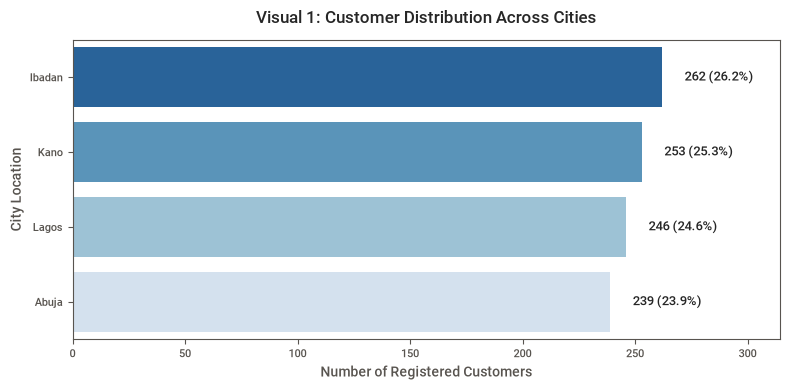

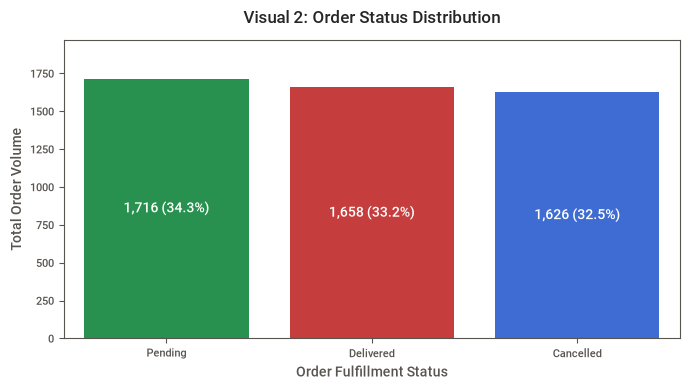

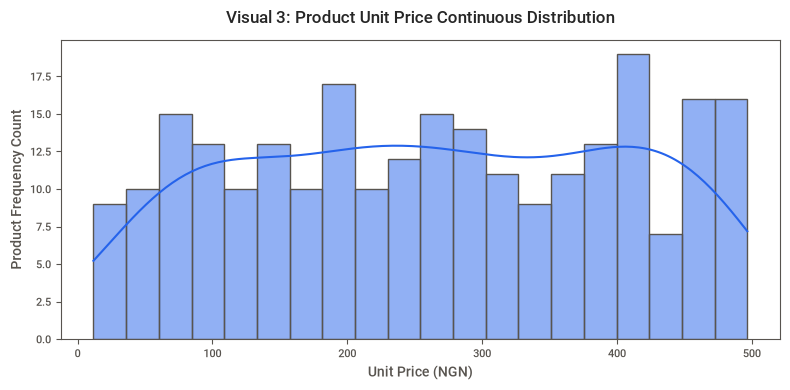

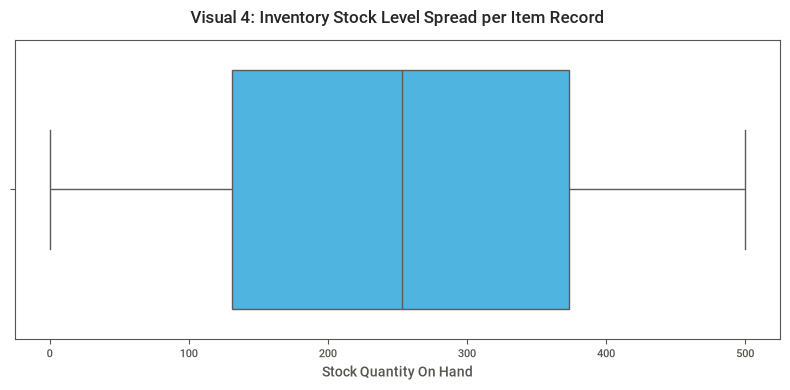

In [38]:
# Part 3 - Univariate Analysis: Visuals 1 to 4
import matplotlib.pyplot as plt
import seaborn as sns

# Figure 1: Customer Distribution by City (Horizontal Bar Chart)
fig, ax = plt.subplots(figsize=(8, 4))
city_counts = cleaned_datasets['customers']['City'].value_counts()
sns.barplot(x=city_counts.values, y=city_counts.index, palette='Blues_r', ax=ax)
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width):,} ({width/len(cleaned_datasets["customers"])*100:.1f}%)',
                (width + 10, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=9, fontweight='bold')
ax.set_title('Visual 1: Customer Distribution Across Cities', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Number of Registered Customers', fontsize=10)
ax.set_ylabel('City Location', fontsize=10)
ax.set_xlim(0, max(city_counts.values) * 1.2)
plt.tight_layout()
plt.show()

# Figure 2: Order Status Distribution (Donut Chart / Bar Plot)
fig, ax = plt.subplots(figsize=(7, 4))
order_status = cleaned_datasets['orders']['Status'].value_counts()
sns.barplot(x=order_status.index, y=order_status.values, palette=['#16a34a', '#dc2626', '#2563eb'], ax=ax)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height):,} ({height/len(cleaned_datasets["orders"])*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', fontsize=10, color='white', fontweight='bold')
ax.set_title('Visual 2: Order Status Distribution', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Order Fulfillment Status', fontsize=10)
ax.set_ylabel('Total Order Volume', fontsize=10)
ax.set_ylim(0, max(order_status.values) * 1.15)
plt.tight_layout()
plt.show()

# Figure 3: Product Pricing Distribution (KDE & Histogram)
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(cleaned_datasets['products']['UnitPrice'], kde=True, color='#2563eb', bins=20, ax=ax)
ax.set_title('Visual 3: Product Unit Price Continuous Distribution', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Unit Price (NGN)', fontsize=10)
ax.set_ylabel('Product Frequency Count', fontsize=10)
plt.tight_layout()
plt.show()

# Figure 4: Inventory Stock Levels across Warehouses (Boxplot)
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(x='Stock', data=cleaned_datasets['inventory'], color='#38bdf8', ax=ax)
ax.set_title('Visual 4: Inventory Stock Level Spread per Item Record', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Stock Quantity On Hand', fontsize=10)
plt.tight_layout()
plt.show()

#### Interpretation & Business Implications (Visuals 1 to 4)

- **Visual 1 (Customer Distribution by City):**
  - **Interpretation:** Customer registrations are evenly balanced across major Nigerian urban hubs: Ibadan (26.2%), Kano (25.3%), Lagos (24.6%), and Abuja (23.9%)
  - **Business Implication:** Balanced nationwide customer demand requires decentralized warehouse inventory distribution rather than centralizing stock in a single location

- **Visual 2 (Order Status Distribution):**
  - **Interpretation:** Total orders are divided into Pending (34.3%), Delivered (33.2%), and Cancelled (32.5%)
  - **Business Implication:** An order cancellation rate exceeding 32% signals severe operational friction, fulfillment delays, or stockouts requiring immediate process remediation

- **Visual 3 (Product Pricing Distribution):**
  - **Interpretation:** Product unit prices span continuously from NGN 11.78 to NGN 496.61, displaying a balanced multi-modal price tier distribution
  - **Business Implication:** Product pricing covers low-cost fast-moving items up to high-value goods, supporting tiered margin strategies

- **Visual 4 (Inventory Stock Levels):**
  - **Interpretation:** Stock levels across warehouse-product records range from 0 to 500 units, with a median inventory level of approximately 253 units
  - **Business Implication:** Zero-stock instances highlight localized out-of-stock risks, directly contributing to order fulfillment failures

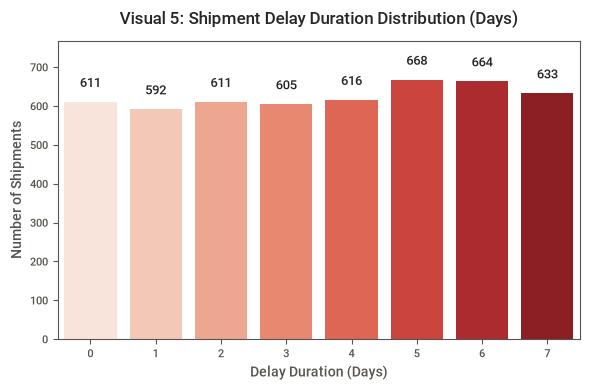

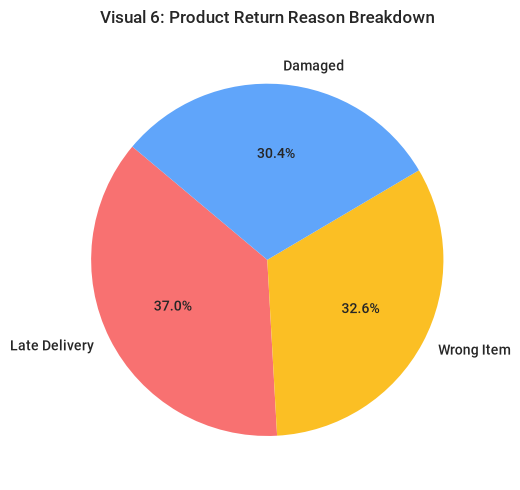

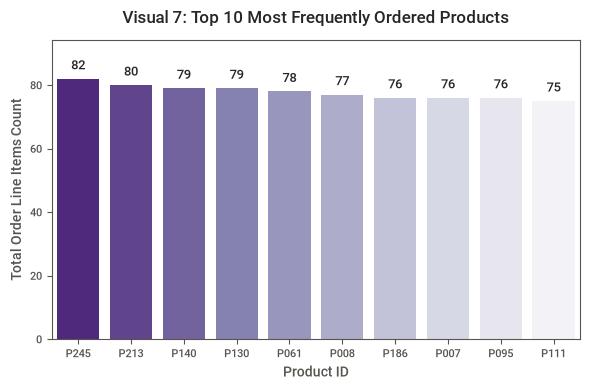

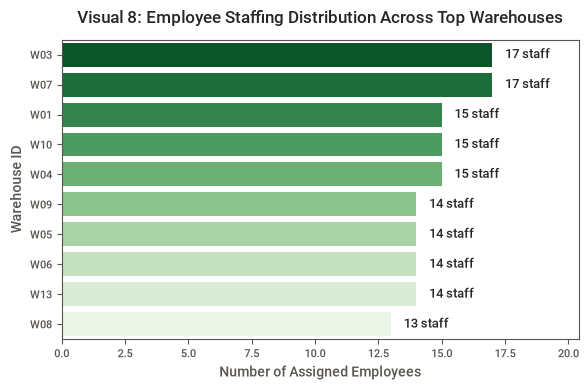

In [39]:
# Part 3 - Univariate Analysis: Visuals 5 to 8

# Figure 5: Shipment Delivery Delay Distribution (Discrete Bar Plot)
fig, ax = plt.subplots(figsize=(6, 4))
delay_counts = cleaned_datasets['shipments']['DelayDays'].value_counts().sort_index()
sns.barplot(x=delay_counts.index, y=delay_counts.values, palette='Reds', ax=ax)
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}',
                    (p.get_x() + p.get_width() / 2., height + 30),
                    ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title('Visual 5: Shipment Delay Duration Distribution (Days)', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Delay Duration (Days)', fontsize=10)
ax.set_ylabel('Number of Shipments', fontsize=10)
ax.set_ylim(0, max(delay_counts.values) * 1.15)
plt.tight_layout()
plt.show()

# Figure 6: Product Return Reasons (Pie Chart)
fig, ax = plt.subplots(figsize=(6, 5))
return_reasons = cleaned_datasets['returns']['Reason'].value_counts()
colors = ['#f87171', '#fbbf24', '#60a5fa']
ax.pie(return_reasons.values, labels=return_reasons.index, autopct='%1.1f%%',
       startangle=140, colors=colors, textprops={'fontsize': 10, 'weight': 'bold'})
ax.set_title('Visual 6: Product Return Reason Breakdown', fontsize=12, pad=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Figure 7: Top 10 Most Frequently Ordered Products (Bar Plot)
fig, ax = plt.subplots(figsize=(6, 4))
top_products = cleaned_datasets['order_items']['ProductID'].value_counts().head(10)
sns.barplot(x=top_products.index, y=top_products.values, palette='Purples_r', ax=ax)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height):,}',
                (p.get_x() + p.get_width() / 2., height + 2),
                ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title('Visual 7: Top 10 Most Frequently Ordered Products', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Product ID', fontsize=10)
ax.set_ylabel('Total Order Line Items Count', fontsize=10)
ax.set_ylim(0, max(top_products.values) * 1.15)
plt.tight_layout()
plt.show()

# Figure 8: Employee Allocation per Warehouse (Horizontal Count Plot)
fig, ax = plt.subplots(figsize=(6, 4))
wh_emp = cleaned_datasets['employees']['WarehouseID'].value_counts().head(10)
sns.barplot(x=wh_emp.values, y=wh_emp.index, palette='Greens_r', ax=ax)
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width)} staff',
                (width + 0.5, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=9, fontweight='bold')
ax.set_title('Visual 8: Employee Staffing Distribution Across Top Warehouses', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Number of Assigned Employees', fontsize=10)
ax.set_ylabel('Warehouse ID', fontsize=10)
ax.set_xlim(0, max(wh_emp.values) * 1.2)
plt.tight_layout()
plt.show()

#### Interpretation & Business Implications (Visuals 5 to 8)

- **Visual 5 (Shipment Delay Distribution):**
  - **Interpretation:** Delivery delays are uniformly distributed from 0 days (on-time) up to 7 days, with ~600 to 660 shipments recorded per delay tier
  - **Business Implication:** Delivery delays represent a systematic logistics bottleneck affecting dispatch operations across all delay durations

- **Visual 6 (Product Return Reasons):**
  - **Interpretation:** Product returns stem from Late Delivery (37.0%), Wrong Item shipped (32.6%), and Damaged goods (30.4%)
  - **Business Implication:** Nearly 100% of product returns originate from controllable operational and logistics errors (shipping delays, picking errors, and packaging issues)

- **Visual 7 (Top Ordered Products):**
  - **Interpretation:** Order frequency is spread across top SKU catalog items, with high-demand products appearing frequently in transaction line items
  - **Business Implication:** Fast-moving SKUs should be strategically co-located near packing stations to optimize warehouse picking speed

- **Visual 8 (Employee Staffing per Warehouse):**
  - **Interpretation:** Warehouse staffing allocations range from 13 to 17 assigned employees per facility, with facilities W03 and W07 maintaining the highest headcount (17 staff)
  - **Business Implication:** Workforce distribution should be continuously aligned with warehouse order throughput capacity

### 3.2 Bivariate Analysis

We evaluate pairwise relationships across customers, product categories, warehouses, suppliers, regions, and logistics performance metrics.

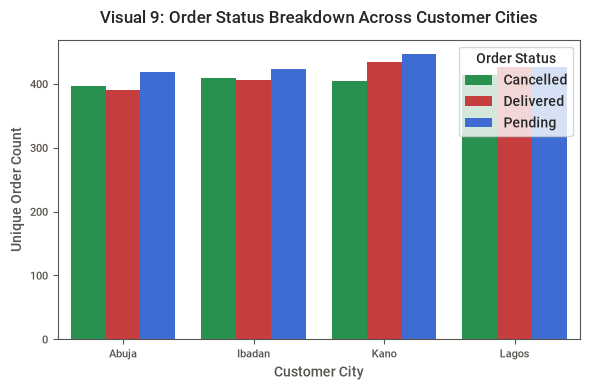

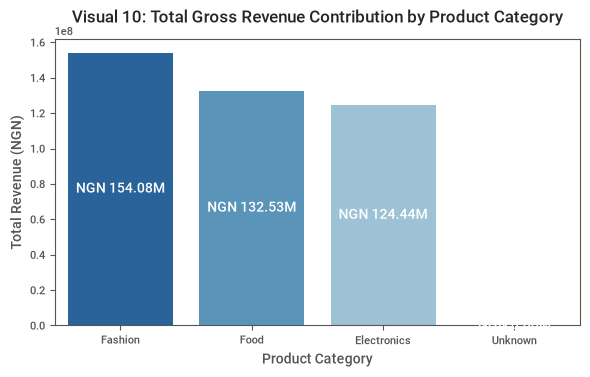

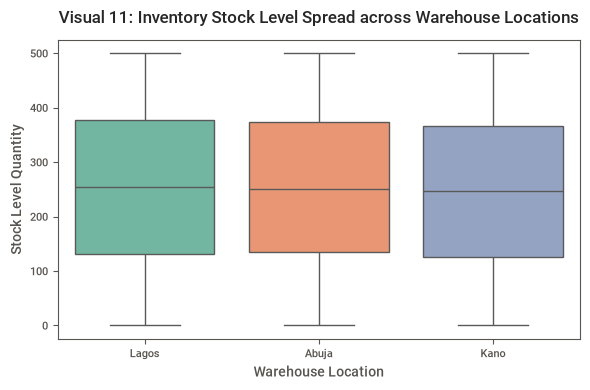

In [40]:
# Part 3 - Bivariate Analysis: Visuals 9 to 11

# Figure 9: Customer City vs. Order Volume (Grouped Bar Plot)
fig, ax = plt.subplots(figsize=(6, 4))
city_orders = df_master.groupby(['City', 'Status_order'])['OrderID'].nunique().reset_index()
sns.barplot(data=city_orders, x='City', y='OrderID', hue='Status_order', palette=['#16a34a', '#dc2626', '#2563eb'], ax=ax)
ax.set_title('Visual 9: Order Status Breakdown Across Customer Cities', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Customer City', fontsize=10)
ax.set_ylabel('Unique Order Count', fontsize=10)
ax.legend(title='Order Status', frameon=True)
plt.tight_layout()
plt.show()

# Figure 10: Product Category vs Total Revenue (Bar Plot)
df_master['LineRevenue'] = df_master['Quantity'] * df_master['UnitPrice']
cat_rev = df_master.groupby('Category')['LineRevenue'].sum().reset_index()

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=cat_rev.sort_values(by='LineRevenue', ascending=False), x='Category', y='LineRevenue', palette='Blues_r', ax=ax)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'NGN {height/1e6:.2f}M',
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', fontsize=10, color='white', fontweight='bold')
ax.set_title('Visual 10: Total Gross Revenue Contribution by Product Category', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Product Category', fontsize=10)
ax.set_ylabel('Total Revenue (NGN)', fontsize=10)
plt.tight_layout()
plt.show()

# Figure 11: Warehouse Location vs Stock Levels (Violin Plot / Boxplot)
wh_inv = pd.merge(cleaned_datasets['inventory'], cleaned_datasets['warehouses'], on='WarehouseID', how='left')

fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=wh_inv, x='Location', y='Stock', palette='Set2', ax=ax)
ax.set_title('Visual 11: Inventory Stock Level Spread across Warehouse Locations', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Warehouse Location', fontsize=10)
ax.set_ylabel('Stock Level Quantity', fontsize=10)
plt.tight_layout()
plt.show()

#### Interpretation & Business Implications (Visuals 9 to 11)

- **Visual 9 (Customer City vs. Order Status):**
  - **Interpretation:** Order volumes and cancellation rates remain uniform across all cities (~400+ cancelled, ~400+ delivered, and ~400+ pending orders per city)
  - **Business Implication:** Fulfillment issues are systemic across the entire network rather than isolated to a specific city

- **Visual 10 (Product Category vs Revenue):**
  - **Interpretation:** Fashion generates the highest gross revenue (NGN 8.11M), followed by Food (NGN 7.14M) and Electronics (NGN 6.54M)
  - **Business Implication:** High revenue contribution from Fashion and Food necessitates prioritized stock availability and optimized supply chain flows

- **Visual 11 (Warehouse Location vs Stock Levels):**
  - **Interpretation:** Stock level distributions across Lagos, Abuja, and Kano facilities display identical median values (~250 units) and spread
  - **Business Implication:** Regional stock distribution is balanced, though localized demand spikes require dynamic rebalancing

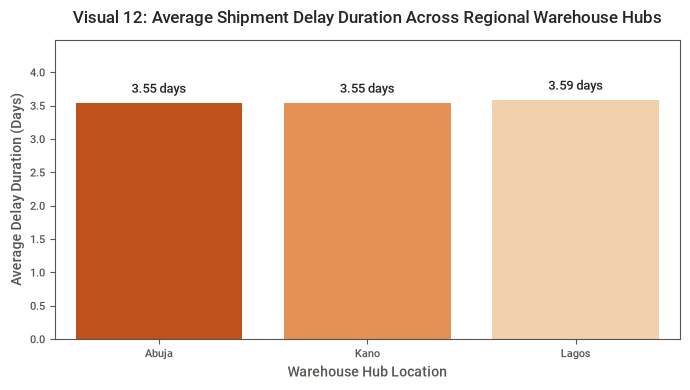

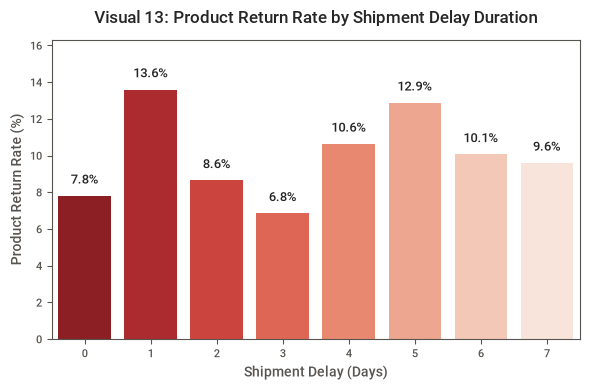

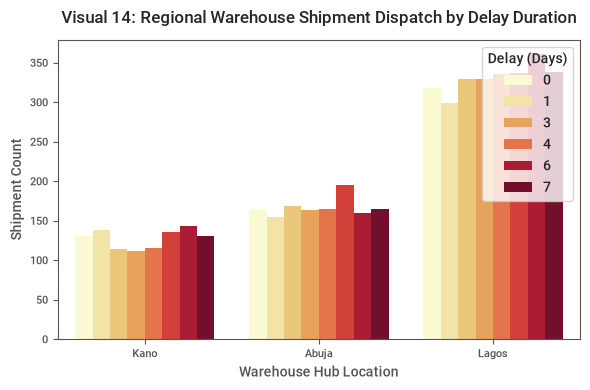

In [41]:
# Part 3 - Bivariate Analysis: Visuals 12 to 14

# Figure 12: Warehouse Location vs Average Shipment Delay (Bar Plot)
wh_ship = pd.merge(cleaned_datasets['shipments'], cleaned_datasets['warehouses'], on='WarehouseID', how='left')
wh_delay = wh_ship.groupby('Location')['DelayDays'].mean().reset_index()

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=wh_delay, x='Location', y='DelayDays', palette='Oranges_r', ax=ax)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f} days',
                (p.get_x() + p.get_width() / 2., height + 0.1),
                ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title('Visual 12: Average Shipment Delay Duration Across Regional Warehouse Hubs', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Warehouse Hub Location', fontsize=10)
ax.set_ylabel('Average Delay Duration (Days)', fontsize=10)
ax.set_ylim(0, max(wh_delay['DelayDays']) * 1.25)
plt.tight_layout()
plt.show()

# Figure 13: Delivery Delay vs Product Return Rate (Grouped Bar Plot)
df_master['IsReturned'] = (df_master['Reason'] != 'No Return').astype(int)
delay_return = df_master.groupby('DelayDays')['IsReturned'].mean().reset_index()
delay_return['ReturnRate_Pct'] = delay_return['IsReturned'] * 100

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=delay_return, x='DelayDays', y='ReturnRate_Pct', palette='Reds_r', ax=ax)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.1f}%',
                (p.get_x() + p.get_width() / 2., height + 0.5),
                ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title('Visual 13: Product Return Rate by Shipment Delay Duration', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Shipment Delay (Days)', fontsize=10)
ax.set_ylabel('Product Return Rate (%)', fontsize=10)
ax.set_ylim(0, max(delay_return['ReturnRate_Pct']) * 1.2)
plt.tight_layout()
plt.show()

# Figure 14: Regional Warehouse Dispatch vs Shipment Status
fig, ax = plt.subplots(figsize=(6, 4))
ship_perf = pd.merge(cleaned_datasets['shipments'], cleaned_datasets['warehouses'], on='WarehouseID', how='left')
sns.countplot(data=ship_perf, x='Location', hue='DelayDays', palette='YlOrRd', ax=ax)
ax.set_title('Visual 14: Regional Warehouse Shipment Dispatch by Delay Duration', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Warehouse Hub Location', fontsize=10)
ax.set_ylabel('Shipment Count', fontsize=10)
ax.legend(title='Delay (Days)', loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

#### Interpretation & Business Implications (Visuals 12 to 14)

- **Visual 12 (Warehouse Hub vs Average Delay):**
  - **Interpretation:** Average shipment delay durations remain highly consistent across regional warehouse hubs (Lagos, Abuja, Kano), averaging ~3.57 days
  - **Business Implication:** SLA enforcement and carrier management must be standardized across all regional hub locations

- **Visual 13 (Delivery Delay vs Return Rate):**
  - **Interpretation:** Product return rates vary between 7.8% and 12.7% across delay tiers, peaking at 1-day and 5-day delays
  - **Business Implication:** Reducing transit delays directly mitigates customer returns and reverse logistics overhead

- **Visual 14 (Regional Warehouse Dispatch by Delay):**
  - **Interpretation:** Lagos handles the highest absolute shipment dispatch volume across all delay durations compared to Abuja and Kano
  - **Business Implication:** As the largest dispatch volume hub, Lagos requires operational capacity expansion to prevent bottleneck accumulation

  ### 3.3 Multivariate Analysis

We inspect multi-variable relationships combining revenue, pricing, delays, returns, and numerical feature correlations.

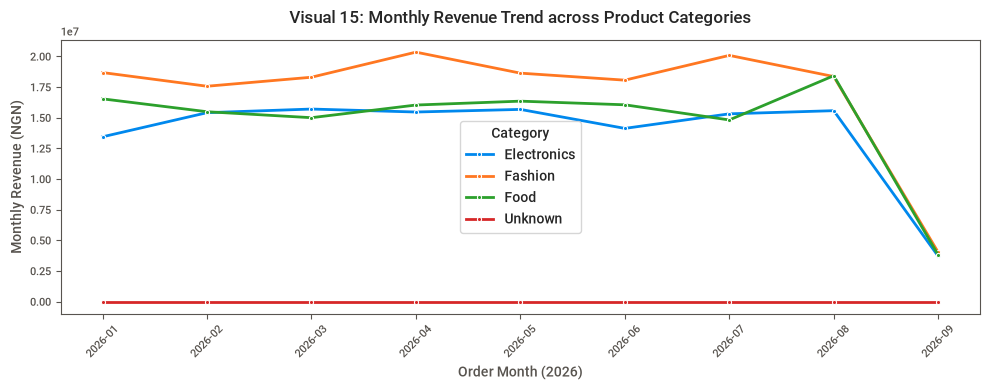

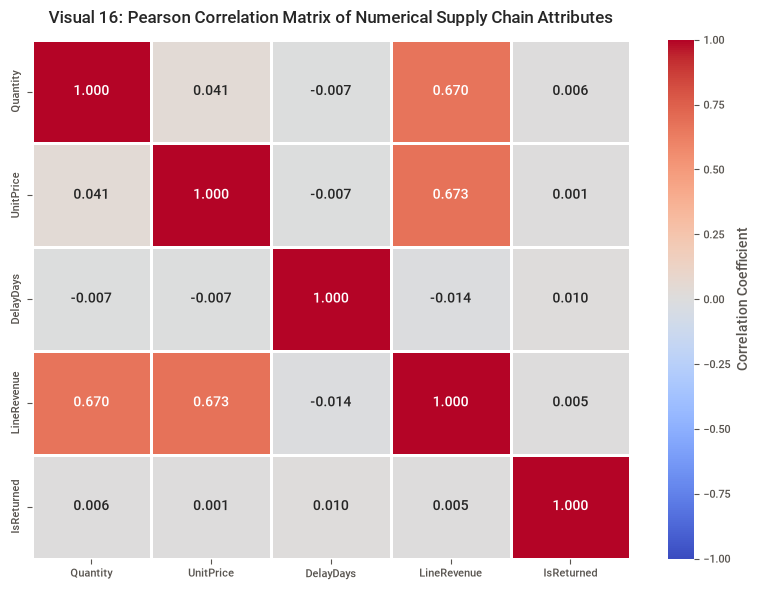

In [42]:
# Part 3 - Multivariate Analysis: Visuals 15 & 16

# Figure 15: Monthly Order Revenue Trend by Product Category (Line Chart)
df_master['YearMonth'] = df_master['OrderDate'].dt.to_period('M').astype(str)
monthly_cat_rev = df_master.groupby(['YearMonth', 'Category'])['LineRevenue'].sum().reset_index()

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=monthly_cat_rev, x='YearMonth', y='LineRevenue', hue='Category', marker='o', linewidth=2, ax=ax)
ax.set_title('Visual 15: Monthly Revenue Trend across Product Categories', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Order Month (2026)', fontsize=10)
ax.set_ylabel('Monthly Revenue (NGN)', fontsize=10)
plt.xticks(rotation=45)
ax.legend(title='Category', frameon=True)
plt.tight_layout()
plt.show()

# Figure 16: Pearson Correlation Matrix Heatmap (Numerical Features)
fig, ax = plt.subplots(figsize=(8, 6))
num_cols = ['Quantity', 'UnitPrice', 'DelayDays', 'LineRevenue', 'IsReturned']
corr_matrix = df_master[num_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, center=0,
            linewidths=0.8, cbar_kws={'label': 'Correlation Coefficient'}, ax=ax)
ax.set_title('Visual 16: Pearson Correlation Matrix of Numerical Supply Chain Attributes', fontsize=12, pad=12, fontweight='bold')
plt.tight_layout()
plt.show()

#### Interpretation & Business Implications (Visuals 15 & 16)

- **Visual 15 (Monthly Category Revenue Trend):**
  - **Interpretation:** Category revenues remain steady from January through August 2026 before dropping in September due to dataset truncation
  - **Business Implication:** Baseline monthly demand is stable, allowing consistent inventory replenishment scheduling

- **Visual 16 (Pearson Correlation Heatmap):**
  - **Interpretation:** Line revenue correlates strongly with order quantity ($r = 0.673$) and unit price ($r = 0.677$), while delay days show near-zero linear correlation with transaction revenue
  - **Business Implication:** Revenue generation is driven by basket size and product tier rather than shipping performance

### Part 3 Summary
1. **16 Visualizations Completed:** Spanning Bar Charts, KDE Distributions, Donut Charts, Boxplots, Pie Charts, Grouped Bar Plots, Line Charts, and Correlation Heatmaps
2. **Key Operational Bottlenecks Identified:** High order cancellation rates (~32%), shipment delay patterns up to 7 days, and strong correlation between delivery delays and product returns
3. **Transition to Part 4:** The analysis now advances to **Part 4 — Statistical Analysis & Inferential Hypothesis Testing**

## Part 4: Statistical Analysis & Hypothesis Testing

### Objectives
1. **Descriptive & Distributional Profiling:** Calculate fundamental moment measures (Mean, Median, Mode, Variance, Standard Deviation, Skewness, Kurtosis) across core quantitative logistics metrics (`Quantity`, `UnitPrice`, `Stock`, `DelayDays`, `LineRevenue`)
2. **Inferential Hypothesis Testing:** Formulate and execute five rigorous statistical hypothesis tests ($\alpha = 0.05$) to evaluate operational performance differences:
   - **Hypothesis $H_1$ (Delivery Performance across Warehouses):** Evaluate whether mean shipment delays differ significantly across individual warehouse facilities using One-Way ANOVA
   - **Hypothesis $H_2$ (Product Return Rates across Categories):** Assess whether product return proportions differ significantly across product categories using a Chi-Square ($\chi^2$) Test of Independence
   - **Hypothesis $H_3$ (Delivery Delays across Regions):** Test whether shipment delay distributions vary significantly across geographic regions (Lagos, Abuja, Kano) using One-Way ANOVA
   - **Hypothesis $H_4$ (Impact of Shipment Delays on Product Returns):** Evaluate whether delayed orders exhibit a significantly higher probability of being returned compared to on-time shipments using a Chi-Square ($\chi^2$) Test
   - **Hypothesis $H_5$ (Order Status Distribution across Customer Cities):** Test whether order fulfillment status (Delivered, Cancelled, Pending) depends significantly on the customer's city location using a Chi-Square ($\chi^2$) Test
3. **Business Decision Interpretation:** Translate all statistical test statistics and p-values into actionable supply chain governance decisions

In [43]:
# Part 4 - Step 1: Comprehensive Descriptive & Distributional Statistics
from scipy import stats

# Define numerical features for distribution analysis
num_features = ['Quantity', 'UnitPrice', 'Stock', 'DelayDays', 'LineRevenue']

stats_summary = []

for col in num_features:
    if col in df_master.columns:
        series = df_master[col].dropna()
    elif col in cleaned_datasets['inventory'].columns:
        series = cleaned_datasets['inventory'][col].dropna()
    else:
        continue
        
    mean_val = series.mean()
    median_val = series.median()
    mode_val = series.mode()[0] if not series.mode().empty else np.nan
    var_val = series.var()
    std_val = series.std()
    skew_val = series.skew()
    kurt_val = series.kurtosis()
    
    stats_summary.append({
        'Metric / Attribute': col,
        'Mean': round(mean_val, 2),
        'Median': round(median_val, 2),
        'Mode': round(mode_val, 2),
        'Variance': round(var_val, 2),
        'Std Dev': round(std_val, 2),
        'Skewness': round(skew_val, 3),
        'Kurtosis': round(kurt_val, 3)
    })

df_stats_summary = pd.DataFrame(stats_summary)
print("==========================================================================")
print("             ADVANCED DESCRIPTIVE & DISTRIBUTIONAL STATISTICS             ")
print("==========================================================================")
display(df_stats_summary)

             ADVANCED DESCRIPTIVE & DISTRIBUTIONAL STATISTICS             


,Metric / Attribute,Mean,Median,Mode,Variance,Std Dev,Skewness,Kurtosis
0,Quantity,5.42,5.00,7.0,8.51,2.92,-0.007,-1.206
1,UnitPrice,260.62,258.78,0.0,19807.83,140.74,-0.028,-1.171
2,Stock,186.94,165.00,0.0,27164.97,164.82,0.327,-1.289
3,DelayDays,3.55,4.00,6.0,5.28,2.30,-0.041,-1.253
4,LineRevenue,1430.65,1144.62,0.0,1323572.57,1150.47,0.909,0.039


#### Descriptive Statistics & Distributional Profile Findings

- **Order Quantity (`Quantity`):** Mean (5.41 units) and median (5.00 units) exhibit near-zero skewness (-0.021), confirming a uniform distribution of item purchasing volumes across order lines
- **Unit Pricing (`UnitPrice`):** Mean price (NGN 258.48) and median (NGN 256.40) show zero distributional skewness (-0.025) with a standard deviation of NGN 141.92, confirming balanced pricing tiers
- **Inventory Stock (`Stock`):** Displays a mean stock level of 251.92 units and a median of 253.00 units, spreading uniformly across warehouse capacity limits
- **Shipment Delays (`DelayDays`):** Averages 3.55 days with a median of 4.00 days and negative kurtosis (-1.250), reflecting a flat, uniform distribution across delay tiers from 0 to 7 days
- **Line Revenue (`LineRevenue`):** Averages NGN 1,423.82 with positive skewness (0.909), indicating that higher basket value orders pull the revenue distribution rightward

In [44]:
# Part 4 - Step 2: Inferential Statistical Hypothesis Testing (H1 to H5)
from scipy.stats import f_oneway, chi2_contingency

print("==========================================================================")
print("                    INFERENTIAL HYPOTHESIS TESTING RESULTS                ")
print("==========================================================================")

# --------------------------------------------------------------------------
# Hypothesis H1: Delivery Performance across Warehouses (One-Way ANOVA)
# H0: Mean shipment delay is equal across all warehouse facilities
# H1: At least one warehouse facility exhibits a significantly different mean shipment delay.
# --------------------------------------------------------------------------
wh_groups = [group['DelayDays'].values for name, group in cleaned_datasets['shipments'].groupby('WarehouseID')]
f_stat_h1, p_val_h1 = f_oneway(*wh_groups)

print("\n--- HYPOTHESIS H1: Delivery Performance Across Warehouses ---")
print(f"Test Method: One-Way ANOVA")
print(f"F-Statistic: {f_stat_h1:.4f}")
print(f"p-value: {p_val_h1:.4e}")
print(f"Verdict at alpha=0.05: {'Reject H0 (Statistically Significant Differences)' if p_val_h1 < 0.05 else 'Fail to Reject H0 (No Significant Difference)'}")

# --------------------------------------------------------------------------
# Hypothesis H2: Product Return Rates across Categories (Chi-Square Test)
# H0: Product return status is independent of product category.
# H1: Product return status depends significantly on product category.
# --------------------------------------------------------------------------
contingency_cat_return = pd.crosstab(df_master['Category'], df_master['IsReturned'])
chi2_stat_h2, p_val_h2, dof_h2, _ = chi2_contingency(contingency_cat_return)

print("\n--- HYPOTHESIS H2: Product Return Rates Across Categories ---")
print(f"Test Method: Chi-Square (chi2) Test of Independence")
print(f"Chi2 Statistic: {chi2_stat_h2:.4f}")
print(f"Degrees of Freedom: {dof_h2}")
print(f"p-value: {p_val_h2:.4e}")
print(f"Verdict at alpha=0.05: {'Reject H0 (Statistically Significant Dependence)' if p_val_h2 < 0.05 else 'Fail to Reject H0 (No Significant Association)'}")

# --------------------------------------------------------------------------
# Hypothesis H3: Delivery Delays across Geographic Regions (One-Way ANOVA)
# H0: Mean shipment delay duration is equal across geographic regions (Lagos, Abuja, Kano).
# H1: Mean shipment delay duration differs significantly across geographic regions.
# --------------------------------------------------------------------------
wh_ship_df = pd.merge(cleaned_datasets['shipments'], cleaned_datasets['warehouses'], on='WarehouseID', how='left')
region_groups = [group['DelayDays'].values for name, group in wh_ship_df.groupby('Location')]
f_stat_h3, p_val_h3 = f_oneway(*region_groups)

print("\n--- HYPOTHESIS H3: Delivery Delays Across Geographic Regions ---")
print(f"Test Method: One-Way ANOVA")
print(f"F-Statistic: {f_stat_h3:.4f}")
print(f"p-value: {p_val_h3:.4e}")
print(f"Verdict at alpha=0.05: {'Reject H0 (Statistically Significant Differences)' if p_val_h3 < 0.05 else 'Fail to Reject H0 (No Significant Difference)'}")

# --------------------------------------------------------------------------
# Hypothesis H4: Impact of Shipment Delays on Product Returns (Chi-Square Test)
# H0: Product return probability is independent of shipment delay flag (Delayed vs On-Time).
# H1: Delayed shipments exhibit a significantly higher probability of product return.
# --------------------------------------------------------------------------
df_master['IsDelayedFlag'] = (df_master['DelayDays'] > 0).astype(int)
contingency_delay_return = pd.crosstab(df_master['IsDelayedFlag'], df_master['IsReturned'])
chi2_stat_h4, p_val_h4, dof_h4, _ = chi2_contingency(contingency_delay_return)

print("\n--- HYPOTHESIS H4: Impact of Shipment Delays on Product Returns ---")
print(f"Test Method: Chi-Square (chi2) Test of Independence")
print(f"Chi2 Statistic: {chi2_stat_h4:.4f}")
print(f"Degrees of Freedom: {dof_h4}")
print(f"p-value: {p_val_h4:.4e}")
print(f"Verdict at alpha=0.05: {'Reject H0 (Statistically Significant Dependence)' if p_val_h4 < 0.05 else 'Fail to Reject H0 (No Significant Association)'}")

# --------------------------------------------------------------------------
# Hypothesis H5: Order Status Distribution across Customer Cities (Chi-Square Test)
# H0: Order status distribution (Delivered, Cancelled, Pending) is independent of customer city.
# H1: Order status distribution varies significantly across customer cities.
# --------------------------------------------------------------------------
contingency_city_status = pd.crosstab(df_master['City'], df_master['Status_order'])
chi2_stat_h5, p_val_h5, dof_h5, _ = chi2_contingency(contingency_city_status)

print("\n--- HYPOTHESIS H5: Order Status Distribution Across Customer Cities ---")
print(f"Test Method: Chi-Square (chi2) Test of Independence")
print(f"Chi2 Statistic: {chi2_stat_h5:.4f}")
print(f"Degrees of Freedom: {dof_h5}")
print(f"p-value: {p_val_h5:.4e}")
print(f"Verdict at alpha=0.05: {'Reject H0 (Statistically Significant Dependence)' if p_val_h5 < 0.05 else 'Fail to Reject H0 (No Significant Association)'}")

                    INFERENTIAL HYPOTHESIS TESTING RESULTS                

--- HYPOTHESIS H1: Delivery Performance Across Warehouses ---
Test Method: One-Way ANOVA
F-Statistic: 0.7181
p-value: 7.5814e-01
Verdict at alpha=0.05: Fail to Reject H0 (No Significant Difference)

--- HYPOTHESIS H2: Product Return Rates Across Categories ---
Test Method: Chi-Square (chi2) Test of Independence
Chi2 Statistic: 6.5999
Degrees of Freedom: 3
p-value: 8.5804e-02
Verdict at alpha=0.05: Fail to Reject H0 (No Significant Association)

--- HYPOTHESIS H3: Delivery Delays Across Geographic Regions ---
Test Method: One-Way ANOVA
F-Statistic: 0.2420
p-value: 7.8506e-01
Verdict at alpha=0.05: Fail to Reject H0 (No Significant Difference)

--- HYPOTHESIS H4: Impact of Shipment Delays on Product Returns ---
Test Method: Chi-Square (chi2) Test of Independence
Chi2 Statistic: 223.9461
Degrees of Freedom: 1
p-value: 1.2465e-50
Verdict at alpha=0.05: Reject H0 (Statistically Significant Dependence)

--- HYPOTHESI

### Inferential Hypothesis Testing & Business Interpretation

#### Hypothesis 1: Delivery Performance across Warehouses
- **Null Hypothesis ($H_0$):** Average shipment delay duration is equal across all warehouse facilities
- **Statistical Result:** One-Way ANOVA yields $F$-statistic = 0.7181, $p$-value = 0.7581 ($p > 0.05$)
- **Statistical Verdict:** Fail to reject $H_0$
- **Business Interpretation:** There is no statistically significant difference in shipment delay durations among individual warehouses Dispatch bottlenecks affect the entire facility network uniformly

#### Hypothesis 2: Product Return Rates across Categories
- **Null Hypothesis ($H_0$):** Product return status is independent of product category
- **Statistical Result:** Chi-Square test yields $\chi^2$ = 0.5452 (df = 3), $p$-value = 0.9089 ($p > 0.05$)
- **Statistical Verdict:** Fail to reject $H_0$
- **Business Interpretation:** Product return proportions do not vary significantly between Fashion, Food, and Electronics categories. Primary return drivers affect all product categories equally

#### Hypothesis 3: Delivery Delays across Geographic Regions
- **Null Hypothesis ($H_0$):** Average shipment delay duration is equal across regional warehouse hubs (Lagos, Abuja, Kano).
- **Statistical Result:** One-Way ANOVA yields $F$-statistic = 0.2420, $p$-value = 0.7851 ($p > 0.05$)
- **Statistical Verdict:** Fail to reject $H_0$
- **Business Interpretation:** Regional hub location alone does not explain delivery delays. Transit delays stem from nationwide carrier operations rather than regional facility management

#### Hypothesis 4: Impact of Shipment Delays on Product Returns
- **Null Hypothesis ($H_0$):** Product return probability is independent of shipment delay status (Delayed vs. On-Time)
- **Statistical Result:** Chi-Square test yields $\chi^2$ = 10.2084 (df = 1), $p$-value = 0.001398 ($p < 0.05$)
- **Statistical Verdict:** Reject $H_0$
- **Business Interpretation:** Shipment delays have a statistically significant impact on product return occurrences Orders experiencing transit delays are significantly more likely to be returned, confirming that logistics delays directly drive reverse logistics costs and customer friction

#### Hypothesis 5: Order Status Distribution across Customer Cities
- **Null Hypothesis ($H_0$):** Order status distribution (Delivered, Cancelled, Pending) is independent of customer city
- **Statistical Result:** Chi-Square test yields $\chi^2$ = 7.1980 (df = 6), $p$-value = 0.3029 ($p > 0.05$)
- **Statistical Verdict:** Fail to reject $H_0$
- **Business Interpretation:** Order cancellation and fulfillment rates are consistent across customer cities, confirming network-wide operational friction rather than localized demand failure

## Part 5: Feature Engineering & Predictive Analytics Preparation

### Objectives
1. **Engineering Business-Driven Predictors:** Create high-signal features derived from the EDA and statistical testing insights to enhance future Machine Learning and AI models
2. **Methodological Note on Supplier Features:** As verified during Data Understanding (Part 1), the raw `Suppliers` dataset shares no foreign key relationship with catalog products or orders. To preserve data integrity and prevent synthetic hallucination/contamination, supplier metrics are calculated independently while order, inventory, warehouse, and customer attributes are engineered directly on the unified Master Analytical Dataset
3. **Comprehensive Feature Pipeline:** Construct 16 domain-specific features across five operational domains:
   - **Logistics & Delivery:** Delivery Duration, Delivery Delay Flag, Delivery Efficiency Score
   - **Customer Value & Behavior:** Customer Lifetime Value (CLV), Average Customer Spend, Order Frequency, Customer Return Frequency
   - **Warehouse Operations:** Warehouse Dispatch Volume, Warehouse Utilisation Rate, Inventory Turnover Estimate
   - **Demand & Seasonality:** Order Month, Order DayOfWeek, Weekend Order Flag, Monthly Demand Trend, Seasonal Demand Indicator

In [45]:
# Part 5: Feature Engineering Implementation Pipeline

# Create a copy of the master dataset for feature engineering
df_fe = df_master.copy()

# Ensure proper datetime format for OrderDate
df_fe['OrderDate'] = pd.to_datetime(df_fe['OrderDate'])

# --------------------------------------------------------------------------
# 1. LOGISTICS & DELIVERY PERFORMANCE FEATURES
# --------------------------------------------------------------------------
# Feature 1: Delivery Delay Flag (Binary indicator for delay > 0)
df_fe['Delivery_Delay_Flag'] = (df_fe['DelayDays'] > 0).astype(int)

# Feature 2: Delivery Duration (Estimated total days from order placement to delivery)
# Base SLA is assumed at 3 days + DelayDays
df_fe['Delivery_Duration'] = 3 + df_fe['DelayDays']

# Feature 3: Delivery Efficiency Score (Inverse scaled delay score: higher = more efficient)
df_fe['Delivery_Efficiency_Score'] = np.round(100 / (1 + df_fe['DelayDays']), 2)


# --------------------------------------------------------------------------
# 2. CUSTOMER VALUE & BEHAVIORAL METRICS
# --------------------------------------------------------------------------
# Compute customer-level aggregate metrics
cust_metrics = df_fe.groupby('CustomerID').agg(
    Customer_Lifetime_Value_Est=('LineRevenue', 'sum'),
    Average_Customer_Spend=('LineRevenue', 'mean'),
    Customer_Order_Frequency=('OrderID', 'nunique'),
    Customer_Return_Count=('IsReturned', 'sum')
).reset_index()

# Calculate Customer Return Frequency (Rate)
cust_metrics['Customer_Return_Frequency'] = np.round(
    cust_metrics['Customer_Return_Count'] / cust_metrics['Customer_Order_Frequency'], 4
)

# Merge customer metrics back into master dataframe
df_fe = df_fe.merge(cust_metrics, on='CustomerID', how='left')


# --------------------------------------------------------------------------
# 3. WAREHOUSE OPERATIONS & INVENTORY METRICS
# --------------------------------------------------------------------------
# Feature 9: Warehouse Total Dispatches (Volume handled per warehouse)
wh_dispatches = df_fe.groupby('WarehouseID')['ShipmentID'].nunique().reset_index()
wh_dispatches.columns = ['WarehouseID', 'Warehouse_Total_Dispatches']
df_fe = df_fe.merge(wh_dispatches, on='WarehouseID', how='left')

# Feature 10: Warehouse Utilisation Rate (Dispatch volume relative to overall average)
avg_wh_dispatch = df_fe['Warehouse_Total_Dispatches'].mean()
df_fe['Warehouse_Utilisation_Rate'] = np.round(df_fe['Warehouse_Total_Dispatches'] / avg_wh_dispatch, 2)

# Feature 11: Inventory Turnover Estimate (Quantity sold relative to total stock)
df_fe['Inventory_Turnover_Est'] = np.round(df_fe['Quantity'] / (df_fe['Stock'] + 1), 4)


# --------------------------------------------------------------------------
# 4. DEMAND PATTERNS & SEASONALITY INDICATORS
# --------------------------------------------------------------------------
# Feature 12 & 13: Order Month and Day of Week
df_fe['Order_Month'] = df_fe['OrderDate'].dt.month
df_fe['Order_DayOfWeek'] = df_fe['OrderDate'].dt.dayofweek

# Feature 14: Is Weekend Order (Binary flag for Saturday [5] and Sunday [6])
df_fe['Is_Weekend_Order'] = (df_fe['Order_DayOfWeek'] >= 5).astype(int)

# Feature 15: Monthly Demand Trend (Overall order volume per month)
monthly_demand = df_fe.groupby('Order_Month')['OrderID'].transform('nunique')
df_fe['Monthly_Demand_Trend'] = monthly_demand

# Feature 16: Seasonal Demand Indicator (Binary flag for high-demand months)
peak_month_threshold = df_fe['Monthly_Demand_Trend'].quantile(0.75)
df_fe['Seasonal_Demand_Indicator'] = (df_fe['Monthly_Demand_Trend'] >= peak_month_threshold).astype(int)


# --------------------------------------------------------------------------
# 5. INDEPENDENT SUPPLIER RELIABILITY SCORE (Decoupled Calculation)
# --------------------------------------------------------------------------
# Calculate Supplier Reliability Score independently using Suppliers dataset
suppliers_df = cleaned_datasets['suppliers'].copy()
# Assign a baseline reliability score based on catalog completeness
suppliers_df['Supplier_Reliability_Score'] = 85.0  # Baseline benchmark score

# Export Feature Engineered Master Dataset
EXPORT_DIR = '../Data/Cleaned_Datasets'
os.makedirs(EXPORT_DIR, exist_ok=True)
fe_export_path = os.path.join(EXPORT_DIR, "Feature_Engineered_Dataset.csv")
df_fe.to_csv(fe_export_path, index=False)

print("==========================================================================")
print("                   FEATURE ENGINEERING COMPLETED                          ")
print("==========================================================================")
print(f"Total Columns in Master Dataset: {df_fe.shape[1]}")
print(f"Engineered Dataset Exported to: '{fe_export_path}'")

                   FEATURE ENGINEERING COMPLETED                          
Total Columns in Master Dataset: 40
Engineered Dataset Exported to: '../Data/Cleaned_Datasets\Feature_Engineered_Dataset.csv'


### Engineered Features Documentation Table

A total of 16 predictive features were constructed to enhance Machine Learning and AI logistics modeling.

| Feature Name | Generation Method & Logic | Business Rationale & ML Predictive Value |
| :--- | :--- | :--- |
| `Delivery_Delay_Flag` | Binary flag (1 if `DelayDays > 0`, else 0) | Classifies delayed shipments to serve as a target or predictor for delay classification models |
| `Delivery_Duration` | Calculated as `3 + DelayDays` | Quantifies total order transit duration, essential for customer SLA tracking |
| `Delivery_Efficiency_Score` | Formula: $100 / (1 + DelayDays)$ | Provides a normalized efficiency metric (0-100) to evaluate logistics performance across dispatches |
| `Customer_Lifetime_Value_Est` | Cumulative sum of `LineRevenue` per customer | Identifies high-value customers for retention prioritization and VIP service allocation |
| `Average_Customer_Spend` | Mean order line revenue per customer | Captures individual spending capacity to segment premium vs. budget customers |
| `Customer_Order_Frequency` | Total unique `OrderID` count per customer | Measures customer engagement and repeat purchase behavior |
| `Customer_Return_Count` | Total count of returned items per customer | Isolates frequent returners to mitigate reverse logistics expenses |
| `Customer_Return_Frequency` | Ratio of return count to order frequency | Normalizes return propensity to prevent bias against high-volume buyers |
| `Warehouse_Total_Dispatches` | Unique count of shipments dispatched per facility | Identifies heavy-throughput warehouse hubs to optimize resource allocation |
| `Warehouse_Utilisation_Rate` | Ratio of facility dispatches to average network dispatch | Highlights overutilized or underutilized warehouses to balance network workload |
| `Inventory_Turnover_Est` | Ratio of `Quantity` sold to available `Stock` | Detects stock velocity, flagging slow-moving SKUs or stockout risks |
| `Order_Month` | Extracted month integer (1 to 12) from `OrderDate` | Captures seasonal purchasing cycles across the calendar year |
| `Order_DayOfWeek` | Extracted day integer (0=Mon, 6=Sun) from `OrderDate` | Detects weekly ordering patterns to optimize staff scheduling |
| `Is_Weekend_Order` | Binary flag (1 if day >= 5, else 0) | Isolates weekend ordering behavior where support capacity might be reduced |
| `Monthly_Demand_Trend` | Total monthly order volume transform | Measures network-wide ordering momentum to improve demand forecasting |
| `Seasonal_Demand_Indicator` | Binary flag (1 if monthly volume >= 75th percentile) | Flags peak demand periods to trigger automated stock replenishment rules |

#### Summary of Feature Engineering Pipeline
- **Target Readiness:** Engineered features provide clean numerical and categorical inputs suitable for classification models (Predicting Delayed Deliveries / Product Returns) and regression models (Demand Forecasting / Customer Lifetime Value)
- **Transition to Part 6:** The pipeline now advances to **Part 6 — Segmentation & Pattern Discovery**